In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Partie 1:Introduction au Dataset

### 1.Téléchargez et chargez le dataset

In [4]:
df=pd.read_excel("titanicDataset")

In [5]:
df.dtypes

pclass         int64
survived       int64
name          object
sex           object
age          float64
sibsp          int64
parch          int64
ticket        object
fare         float64
cabin         object
embarked      object
boat          object
body         float64
home.dest     object
dtype: object

In [6]:
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [7]:
df.isnull().sum()

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64

# Partie 2:Nettoyage des Données

In [8]:
df.isnull().sum()[df.isnull().sum()>0]


age           263
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64


### 1 Gestion des valeurs manquantes:

In [9]:
(df.isnull().sum()/len(df)*100).sort_values(ascending=False)


body         90.756303
cabin        77.463713
boat         62.872422
home.dest    43.086325
age          20.091673
embarked      0.152788
fare          0.076394
sibsp         0.000000
name          0.000000
survived      0.000000
pclass        0.000000
sex           0.000000
parch         0.000000
ticket        0.000000
dtype: float64

In [10]:
df=df.drop(["name","sibsp","parch","ticket","cabin","boat","body","home.dest"],axis=1)

In [11]:
df=df.fillna(df['age'].mean())
df=df.fillna(df['fare'].median())
df.head()

,pclass,survived,sex,age,fare,embarked
0,1,1,female,29.0000,211.3375,S
1,1,1,male,0.9167,151.5500,S
2,1,0,female,2.0000,151.5500,S
3,1,0,male,30.0000,151.5500,S
4,1,0,female,25.0000,151.5500,S


### 2. Gestion des valeurs aberrantes:

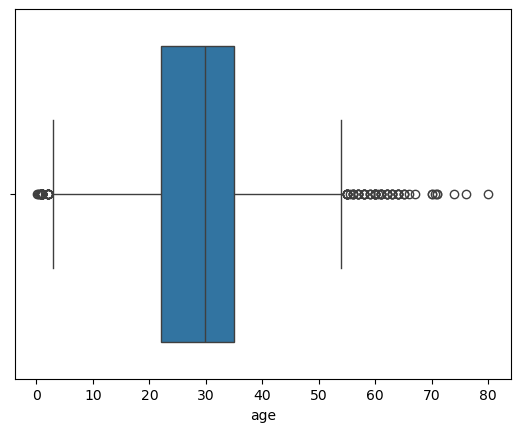

In [12]:
sns.boxplot(x=df['age'])
plt.show()

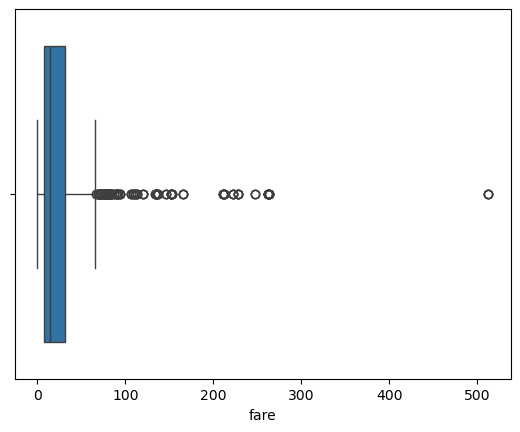

In [13]:
sns.boxplot(x=df['fare'])
plt.show()

#### .Remplacez les valeur aberrantes

In [14]:
Q1_age=df["age"].quantile(0.25)
Q3_age=df["age"].quantile(0.75)
IQR_age=Q3_age-Q1_age
borne_inf_age=Q1_age-1.5*IQR_age
borne_sup_age=Q3_age+1.5*IQR_age
df["age"]=df["age"].clip(lower=borne_inf_age,upper=borne_sup_age)


In [15]:
Q1_fare=df["fare"].quantile(0.25)
Q3_fare=df["fare"].quantile(0.75)
IQR_fare=Q3_fare-Q1_fare
borne_inf_fare=Q1_fare-1.5*IQR_fare
borne_sup_fare=Q3_fare+1.5*IQR_fare
df["fare"]=df["fare"].clip(lower=borne_inf_fare,upper=borne_sup_fare)

# Partie 3:Transformation des Données

### 1.Encodage des varaibles catégorielles:

In [16]:
encoder=pd.get_dummies(df, columns=['sex'])
encoder_embarked=pd.get_dummies(df, columns=['embarked'])

In [17]:
encoder.head()

,pclass,survived,age,fare,embarked,sex_female,sex_male
0,1,1,29.0,66.3438,S,True,False
1,1,1,2.5,66.3438,S,False,True
2,1,0,2.5,66.3438,S,True,False
3,1,0,30.0,66.3438,S,False,True
4,1,0,25.0,66.3438,S,True,False


In [18]:
encoder_embarked.head()

,pclass,survived,sex,age,fare,embarked_29.8811345124283,embarked_C,embarked_Q,embarked_S
0,1,1,female,29.0,66.3438,False,False,False,True
1,1,1,male,2.5,66.3438,False,False,False,True
2,1,0,female,2.5,66.3438,False,False,False,True
3,1,0,male,30.0,66.3438,False,False,False,True
4,1,0,female,25.0,66.3438,False,False,False,True


### 2.Normalisation  et Standardisation des données:

In [19]:
from sklearn.preprocessing  import MinMaxScaler
from sklearn.preprocessing  import StandardScaler

In [20]:
####Normalisation (Min-Max scaling)
Scaler=MinMaxScaler()
norm=Scaler.fit_transform(df[['age','fare']])

In [21]:
#####Standardisation (Z-score)
Scaler_stand= StandardScaler()
stand=Scaler_stand.fit_transform(df[['age','fare']])

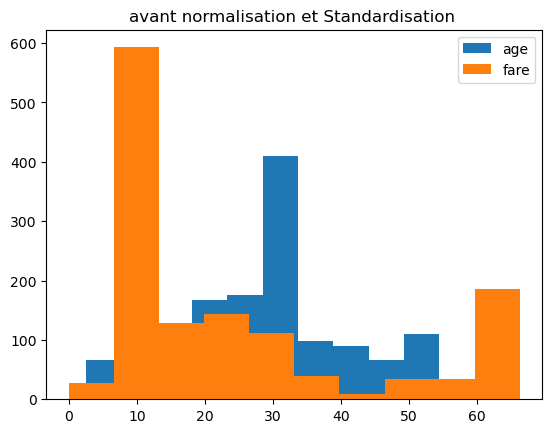

In [22]:
plt.title("avant normalisation et Standardisation ")
plt.hist(df['age'],label="age")
plt.hist(df['fare'],label="fare")
plt.legend()

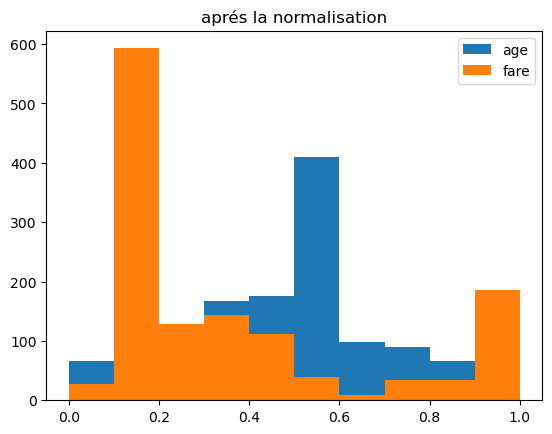

In [23]:
plt.title("aprés la normalisation")
plt.hist(norm[:,0],label="age")
plt.hist(norm[:,1],label="fare")
plt.legend()

#### en canclu
##### dans le cas de normalisation les valeurs soient dans [0,1]

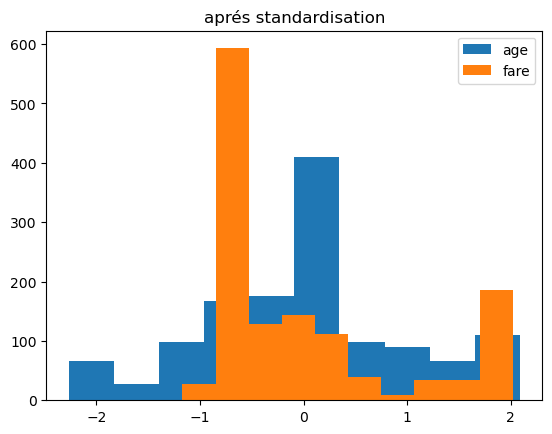

In [24]:
plt.title("aprés standardisation")
plt.hist(stand[:,0],label="age")
plt.hist(stand[:,1],label="fare")
plt.legend()

#### en canclu
##### dans le cas de standardisation les valeurs soient dans [-3,3[

# Partie 4 :Gestion des Données Déséquilibrées

## 1.Identification du déséquilibre des classes:

In [25]:
df['survived'].value_counts()

survived
0    809
1    500
Name: count, dtype: int64

### 2.Gestion du déséquilibre

#### .Sous-échantillonnage

In [28]:
from sklearn.utils import resample
majo=df[df['survived']==0]
mino=df[df['survived']==1]
majo1=resample (majo,replace=False,n_samples=len(mino),random_state=0)
d=pd.concat([majo1,mino])
d["survived"].value_counts()

survived
0    500
1    500
Name: count, dtype: int64

#### . sur-échantillonnage

In [31]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
X = df[['pclass', 'age', 'fare', 'sex']].copy()
y = df['survived']
X['sex'] = X['sex'].map({'male': 0, 'female': 1})
X['age']=X['age'].fillna(X['age'].median())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
smote = SMOTE(random_state=0)
X_train_result, y_train_result = smote.fit_resample(X_train, y_train)
print("Avant SMOTE:", y_train.value_counts().to_dict())
print("Après SMOTE:", pd.Series(y_train_result).value_counts().to_dict())

Avant SMOTE: {0: 647, 1: 400}
Après SMOTE: {0: 647, 1: 647}


##### on identifiez du déséquilibre survie a 500 et les morts a 809
#### et on appliqué le somte sur le trian ce qui equilibré les classes les morts a 500 et les survies a 500